In [3]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, classification_report, precision_recall_curve
)
from xgboost import XGBClassifier
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)

CSV_PATH = "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df_raw = pd.read_csv(CSV_PATH)
print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
df_raw.head()

Dataset Shape: 7043 rows, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print(f"Duplicate Rows     : {df_raw.duplicated().sum()}")
print(f"Unique customerIDs : {df_raw['customerID'].nunique()}")

audit_records = []
for col in df_raw.columns:
    std_nulls = df_raw[col].isnull().sum()
    whitespace_nulls = (
        (df_raw[col].astype(str).str.strip() == "").sum()
        if df_raw[col].dtype == "object"
        else 0
    )
    audit_records.append({
        "Column": col,
        "Dtype": str(df_raw[col].dtype),
        "Std_Nulls": std_nulls,
        "Whitespace_Blank": whitespace_nulls,
        "Unique_Values": df_raw[col].nunique(),
        "Sample_Values": str(df_raw[col].unique()[:3]),
    })

display(pd.DataFrame(audit_records))

# Inspect hidden blank strings in TotalCharges
blank_mask = df_raw["TotalCharges"].astype(str).str.strip() == ""
print(f"\nFound {blank_mask.sum()} rows where TotalCharges is a blank string (' '):")
display(df_raw.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]])

Duplicate Rows     : 0
Unique customerIDs : 7043


,Column,Dtype,Std_Nulls,Whitespace_Blank,Unique_Values,Sample_Values
0,customerID,str,0,0,7043,"<StringArray>\n['7590-VHVEG', '5575-GNVDE', '3..."
1,gender,str,0,0,2,"<StringArray>\n['Female', 'Male']\nLength: 2, ..."
2,SeniorCitizen,int64,0,0,2,[0 1]
3,Partner,str,0,0,2,"<StringArray>\n['Yes', 'No']\nLength: 2, dtype..."
4,Dependents,str,0,0,2,"<StringArray>\n['No', 'Yes']\nLength: 2, dtype..."
5,tenure,int64,0,0,73,[ 1 34 2]
6,PhoneService,str,0,0,2,"<StringArray>\n['No', 'Yes']\nLength: 2, dtype..."
7,MultipleLines,str,0,0,3,"<StringArray>\n['No phone service', 'No', 'Yes..."
8,InternetService,str,0,0,3,"<StringArray>\n['DSL', 'Fiber optic', 'No']\nL..."
9,OnlineSecurity,str,0,0,3,"<StringArray>\n['No', 'Yes', 'No internet serv..."



Found 11 rows where TotalCharges is a blank string (' '):


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


,Count,Percentage (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


,count,mean,std,min,50%,max,skewness,IQR_Outliers
tenure,7043.0,32.37,24.56,0.00,29.00,72.00,0.24,7043
MonthlyCharges,7043.0,64.76,30.09,18.25,70.35,118.75,-0.22,7043
TotalCharges_numeric,7032.0,2283.30,2266.77,18.80,1397.48,8684.80,0.96,7032


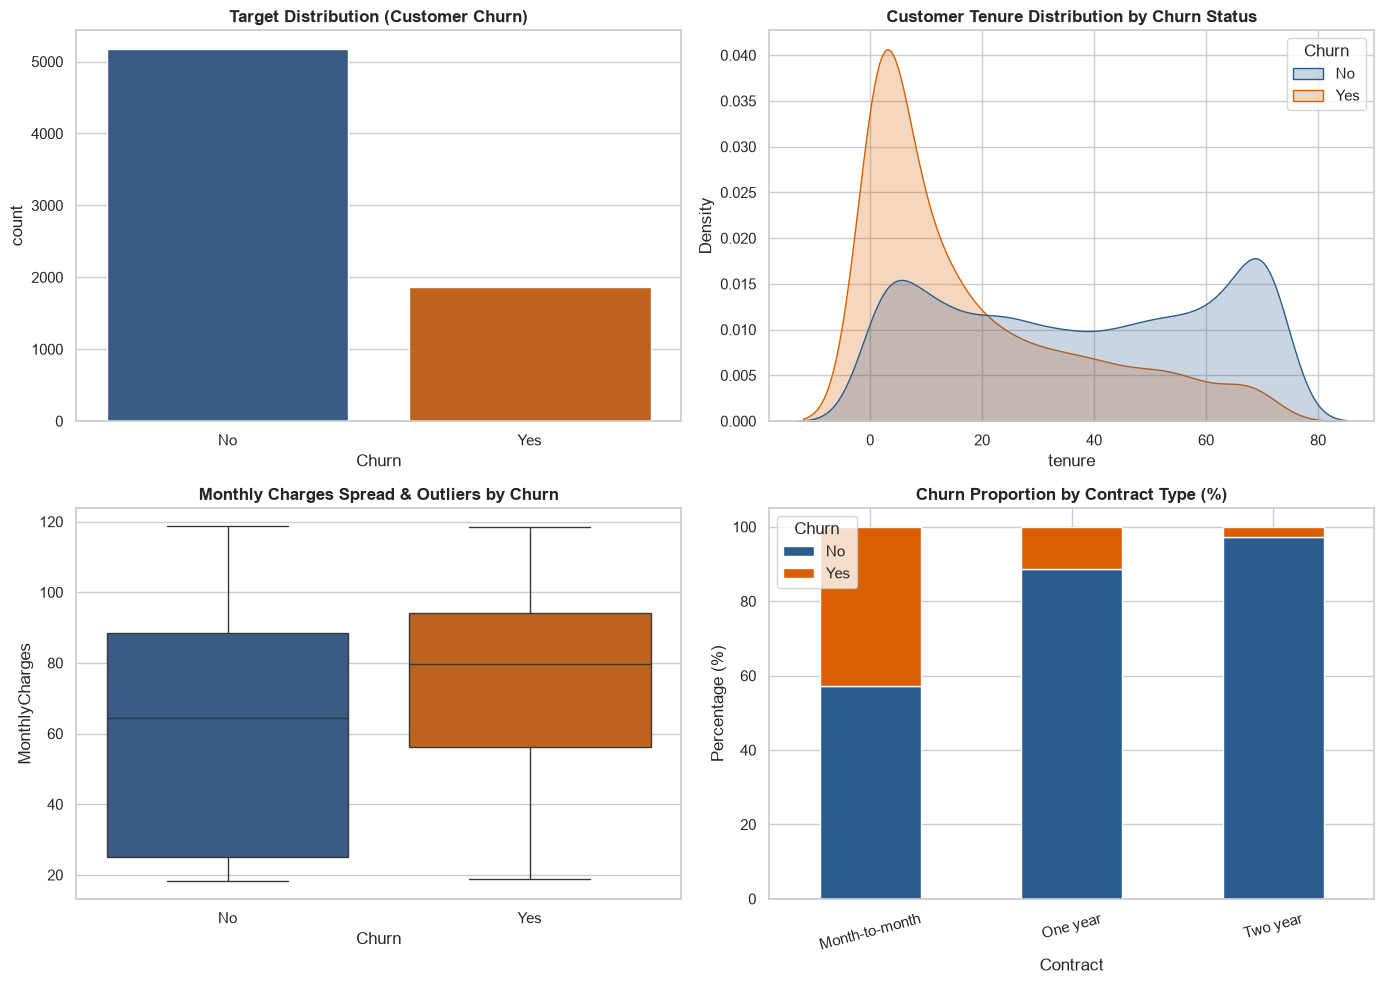

In [5]:
display(pd.DataFrame({
    "Count": df_raw["Churn"].value_counts(),
    "Percentage (%)": (df_raw["Churn"].value_counts(normalize=True) * 100).round(2)
}))

temp_num = df_raw[["tenure", "MonthlyCharges"]].copy()
temp_num["TotalCharges_numeric"] = pd.to_numeric(df_raw["TotalCharges"], errors="coerce")

desc = temp_num.describe().T[["count", "mean", "std", "min", "50%", "max"]]
desc["skewness"] = temp_num.skew()
desc["IQR_Outliers"] = [
    ((s < s.quantile(0.25) - 1.5 * (s.quantile(0.75) - s.quantile(0.25))) |
     (s > s.quantile(0.75) + 1.5 * (s.quantile(0.25) - s.quantile(0.75)))).sum()
    for s in [temp_num[c].dropna() for c in temp_num.columns]
]
display(desc.round(2))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.countplot(data=df_raw, x="Churn", palette=["#2b5c8f", "#d95f02"], ax=axes[0, 0])
axes[0, 0].set_title("Target Distribution (Customer Churn)", fontweight="bold")

sns.kdeplot(data=df_raw, x="tenure", hue="Churn", fill=True, common_norm=False, palette=["#2b5c8f", "#d95f02"], ax=axes[0, 1])
axes[0, 1].set_title("Customer Tenure Distribution by Churn Status", fontweight="bold")

sns.boxplot(data=df_raw, x="Churn", y="MonthlyCharges", palette=["#2b5c8f", "#d95f02"], ax=axes[1, 0])
axes[1, 0].set_title("Monthly Charges Spread & Outliers by Churn", fontweight="bold")

contract_churn = df_raw.groupby("Contract")["Churn"].value_counts(normalize=True).unstack().fillna(0) * 100
contract_churn.plot(kind="bar", stacked=True, color=["#2b5c8f", "#d95f02"], ax=axes[1, 1])
axes[1, 1].set_title("Churn Proportion by Contract Type (%)", fontweight="bold")
axes[1, 1].set_ylabel("Percentage (%)")
axes[1, 1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig("outputs/eda_overview.png", dpi=150)
plt.show()

In [6]:
df_clean = df_raw.copy()

if "customerID" in df_clean.columns:
    df_clean.drop(columns=["customerID"], inplace=True)

df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce").fillna(0.0)
df_clean["SeniorCitizen"] = df_clean["SeniorCitizen"].map({0: "No", 1: "Yes"}).astype(str)

replace_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
for col in replace_cols:
    df_clean[col] = df_clean[col].replace({"No internet service": "No"})
df_clean["MultipleLines"] = df_clean["MultipleLines"].replace({"No phone service": "No"})

df_clean["Churn"] = df_clean["Churn"].map({"Yes": 1, "No": 0}).astype(int)
print("Cleaned dataset shape:", df_clean.shape)

Cleaned dataset shape: (7043, 20)


In [7]:
df_feat = df_clean.copy()

avg_historical_charge = df_feat["TotalCharges"] / (df_feat["tenure"] + 1e-5)
df_feat["charge_to_historical_ratio"] = np.where(
    df_feat["tenure"] == 0, 1.0, df_feat["MonthlyCharges"] / (avg_historical_charge + 1e-5)
)

addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df_feat["total_addons"] = (df_feat[addon_cols] == "Yes").sum(axis=1)

df_feat["is_high_risk_segment"] = (
    (df_feat["Contract"] == "Month-to-month") & (df_feat["PaymentMethod"] == "Electronic check")
).astype(str)

X = df_feat.drop(columns=["Churn"])
y = df_feat["Churn"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

def build_preprocessor(df_input):
    num_cols = df_input.select_dtypes(include=["int64", "float64"]).columns.tolist()
    cat_cols = df_input.select_dtypes(include=["object", "category"]).columns.tolist()
    return ColumnTransformer(transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ])

print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}")

Train shape: (5634, 22) | Test shape: (1409, 22)


In [8]:
def find_optimal_f1_threshold(y_true, y_probs):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_probs)
    f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-8)
    best_idx = np.argmax(f1_scores[:-1])
    return float(thresholds[best_idx])

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression (Baseline)": Pipeline([
        ("preprocessor", build_preprocessor(X_train)),
        ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
    ]),
    "XGBoost (Tuned Class Weight)": Pipeline([
        ("preprocessor", build_preprocessor(X_train)),
        ("classifier", XGBClassifier(
            n_estimators=250, max_depth=4, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, scale_pos_weight=scale_pos_weight,
            eval_metric="logloss", random_state=42,
        )),
    ]),
}

best_model, best_roc_auc = None, 0.0

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_probs = pipeline.predict_proba(X_test)[:, 1]
    opt_thresh = find_optimal_f1_threshold(y_test, y_probs)
    y_pred = (y_probs >= opt_thresh).astype(int)

    roc_auc = roc_auc_score(y_test, y_probs)
    pr_auc = average_precision_score(y_test, y_probs)
    print(f"\n---> {name}")
    print(f"ROC-AUC: {roc_auc:.4f} | PR-AUC: {pr_auc:.4f} | Threshold: {opt_thresh:.4f}")
    print(classification_report(y_test, y_pred, target_names=["Retained (0)", "Churned (1)"]))

    if roc_auc > best_roc_auc:
        best_roc_auc = roc_auc
        best_model = pipeline

joblib.dump(best_model, "outputs/best_churn_model.joblib")


---> Logistic Regression (Baseline)
ROC-AUC: 0.8419 | PR-AUC: 0.6350 | Threshold: 0.5683
              precision    recall  f1-score   support

Retained (0)       0.89      0.77      0.83      1035
 Churned (1)       0.54      0.74      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409


---> XGBoost (Tuned Class Weight)
ROC-AUC: 0.8414 | PR-AUC: 0.6615 | Threshold: 0.6125
              precision    recall  f1-score   support

Retained (0)       0.88      0.82      0.85      1035
 Churned (1)       0.59      0.69      0.63       374

    accuracy                           0.79      1409
   macro avg       0.73      0.76      0.74      1409
weighted avg       0.80      0.79      0.79      1409



['outputs/best_churn_model.joblib']

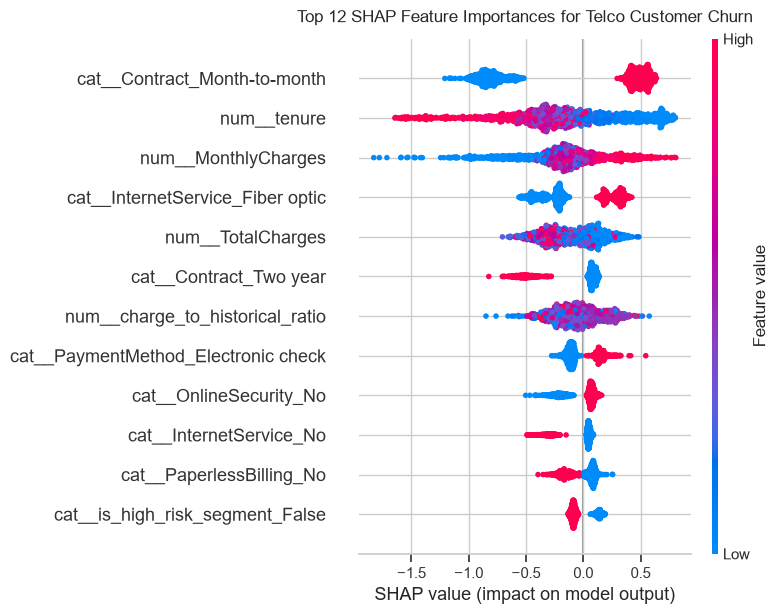

In [9]:
xgb_pipe = models["XGBoost (Tuned Class Weight)"]
X_test_transformed = xgb_pipe.named_steps["preprocessor"].transform(X_test)
feature_names = xgb_pipe.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(xgb_pipe.named_steps["classifier"])
shap_values = explainer.shap_values(X_test_transformed)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, show=False, max_display=12)
plt.title("Top 12 SHAP Feature Importances for Telco Customer Churn", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("outputs/shap_summary.png", dpi=150)
plt.show()